#### ***Non-LLM Workflow (Temperature Converter)***

In [1]:
import warnings 
warnings.filterwarnings("ignore")

from langgraph.graph import StateGraph, START, END
from typing import TypedDict

# Define State  
class TempState(TypedDict):
    temp_celsius : float
    temp_fahrenheit : float
    weather_status : str 

In [2]:
## Node (Simple Workflow)
def convert_temp(state:TempState) -> TempState:
    celsius = state['temp_celsius']
    
    fahrenhite = (celsius * 9/5) + 32 
    state['temp_fahrenheit'] = round(fahrenhite,2)
    return state

In [3]:
## Node (Label Weather Condition)
def label_weather(state:TempState) -> TempState:
    fahrenheit = state['temp_fahrenheit']
    if fahrenheit < 50:
        state["weather_status"] = "Cold"
    elif 50 <= fahrenheit < 77:
        state["weather_status"] = "Mild"
    elif 77 <= fahrenheit < 95:
        state["weather_status"] = "Hot"
    else:
        state["weather_status"] = "Extreme Heat"
    return state

- ***Define & Compile Graph*** 

In [4]:
# define graph
graph = StateGraph(TempState)

# add nodes
graph.add_node('convert_temp',convert_temp)
graph.add_node('label_weather',label_weather)

# add edges 
graph.add_edge(START,'convert_temp')
graph.add_edge('convert_temp','label_weather')
graph.add_edge('label_weather',END)

# compile graph 
workflow = graph.compile()

- ***Execute Graph***

In [5]:
initial_state = {'temp_celsius':28.3}
final_state = workflow.invoke(initial_state)
print(final_state)

{'temp_celsius': 28.3, 'temp_fahrenheit': 82.94, 'weather_status': 'Hot'}


- ***Visualize Graph***

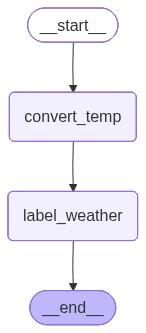

In [6]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

#### ***LLm Workflow (Simple QA Chatbot)***

In [7]:
from langgraph.graph import StateGraph,START,END 
from langchain_groq import ChatGroq
from typing import TypedDict 

from dotenv import load_dotenv
load_dotenv()

True

In [8]:
# Define Our Model
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

# Define State  
class LLM_State(TypedDict):
    question:str 
    answer:str

In [9]:
## Creating Node
def llm_qa(state:LLM_State) -> LLM_State:
    question = state['question']
    prompt = f"answer the following question {question}"
    answer = llm.invoke(prompt).content 
    state['answer'] = answer
    return state

In [10]:
# Compile Graph  
graph = StateGraph(LLM_State)

graph.add_node('llm_qa',llm_qa)

graph.add_edge(START,'llm_qa')
graph.add_edge('llm_qa',END)

workflow = graph.compile()

In [11]:
# Execute Graph 
initial_state = {'question':'who i creator of python and how python evolve in AIML domain'}
final_state = workflow.invoke(initial_state)
print(final_state['answer'])

**Creator of Python**  
- **Guido van Rossum** is the original creator of the Python programming language. He started developing Python in December 1989 at the Centrum Wiskunde & Informatica (CWI) in the Netherlands, and the first public release (Python 0.9.0) appeared in February 1991. Guido remained the “Benevolent Dictator For Life” (BDFL) of the language until he stepped down in 2018.

---

## How Python Evolved in the AI/ML Domain

| Era | Milestones & Why Python Gained Traction in AI/ML |
|-----|---------------------------------------------------|
| **1990s – Early 2000s** | • Python’s clean syntax and dynamic typing made rapid prototyping easy.<br>• Early scientific libraries such as **NumPy** (2005) and **SciPy** (2001) provided fast array operations and numerical routines, laying the groundwork for data‑centric work. |
| **2006 – 2010** | • **scikit‑learn** (released 2010) offered a unified, easy‑to‑use API for classic machine‑learning algorithms (regression, classification, c

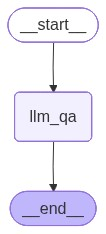

In [12]:
## Visualize Our Graph 
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())